# Plotly: Interactive Data Visualization

## What is Plotly?
**Plotly** is an open-source interactive visualization library for Python (and R, JavaScript). Created by **Plotly Inc.** in 2012, it produces interactive, web-based charts rendered with D3.js/WebGL.

### Plotly vs Matplotlib vs Seaborn
| Feature | Matplotlib | Seaborn | Plotly |
|---------|-----------|---------|--------|
| Interactivity | None | None | Built-in (zoom, hover, pan) |
| Output | Static | Static | HTML/web |
| 3D | Limited | None | Full 3D |
| Dashboards | No | No | Yes (Dash) |
| Learning curve | Medium | Low | Medium |

### Two APIs
| API | Module | Style |
|-----|--------|-------|
| **Plotly Express (px)** | `plotly.express` | High-level, one-line charts |
| **Graph Objects (go)** | `plotly.graph_objects` | Low-level, full control |

In [1]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd
import numpy as np
print('Plotly imported successfully')
# Plotly renders interactively in Jupyter use .show() to display

Plotly imported successfully


## 1. Plotly Express Quick Charts

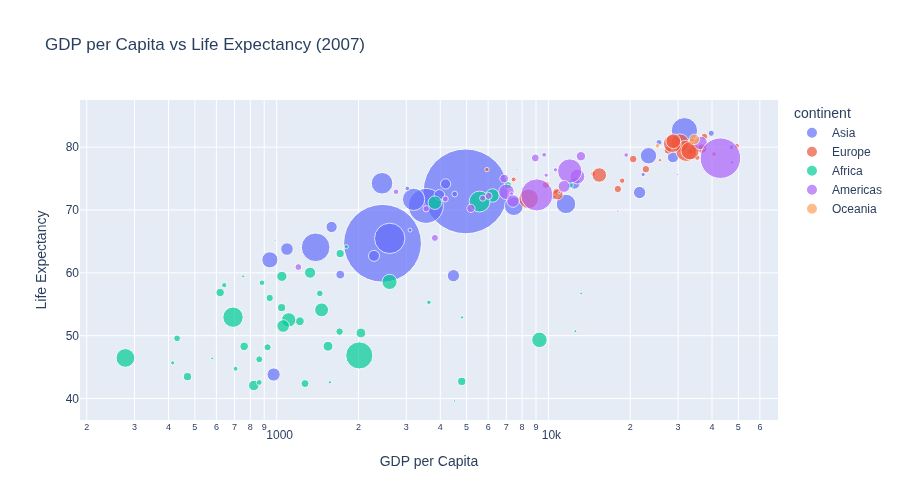

In [2]:
df = px.data.gapminder()
df_2007 = df[df['year'] == 2007]

# Scatter plot
fig = px.scatter(
    df_2007,
    x='gdpPercap', y='lifeExp',
    size='pop', color='continent',
    hover_name='country',
    log_x=True, size_max=60,
    title='GDP per Capita vs Life Expectancy (2007)',
    labels={'gdpPercap': 'GDP per Capita', 'lifeExp': 'Life Expectancy'}
)
fig.show()

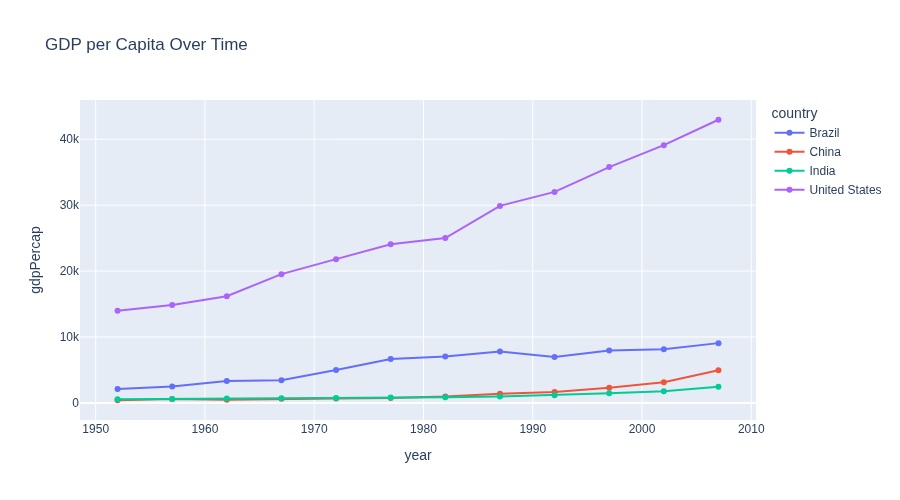

In [3]:
# Line chart
df_countries = df[df['country'].isin(['United States', 'China', 'India', 'Brazil'])]
fig = px.line(
    df_countries,
    x='year', y='gdpPercap',
    color='country', markers=True,
    title='GDP per Capita Over Time'
)
fig.update_traces(line_width=2)
fig.show()

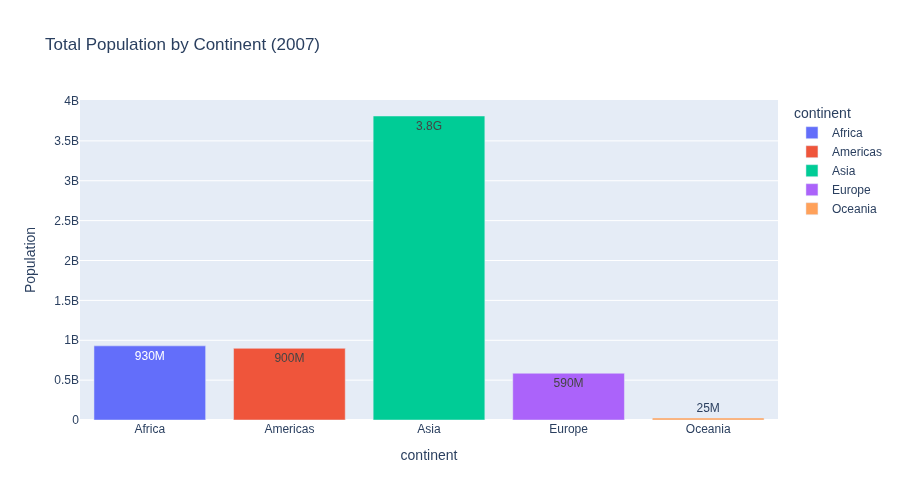

In [4]:
# Bar chart
df_bar = df_2007.groupby('continent')['pop'].sum().reset_index()
fig = px.bar(
    df_bar, x='continent', y='pop',
    color='continent',
    title='Total Population by Continent (2007)',
    labels={'pop': 'Population'},
    text_auto='.2s'
)
fig.show()

## 2. Distribution Charts

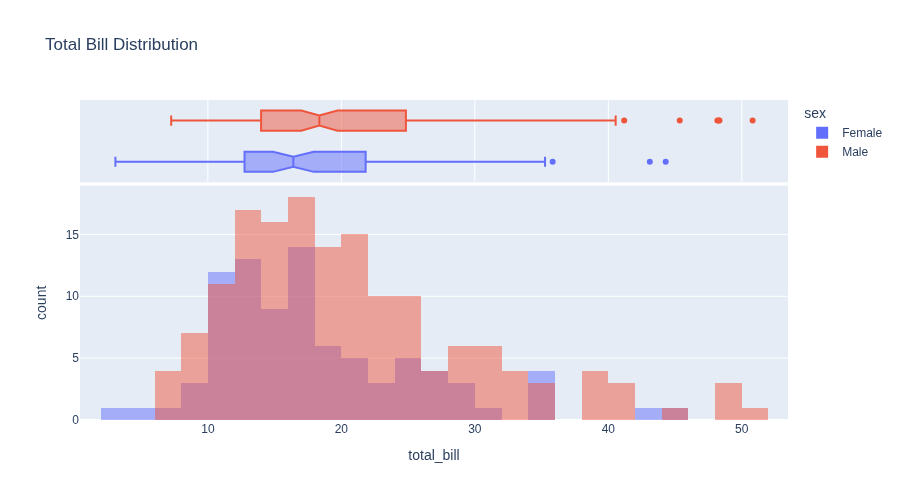

In [5]:
tips = px.data.tips()

# Histogram
fig = px.histogram(
    tips, x='total_bill',
    color='sex', barmode='overlay',
    marginal='box',  # adds a box plot on top
    title='Total Bill Distribution'
)
fig.show()

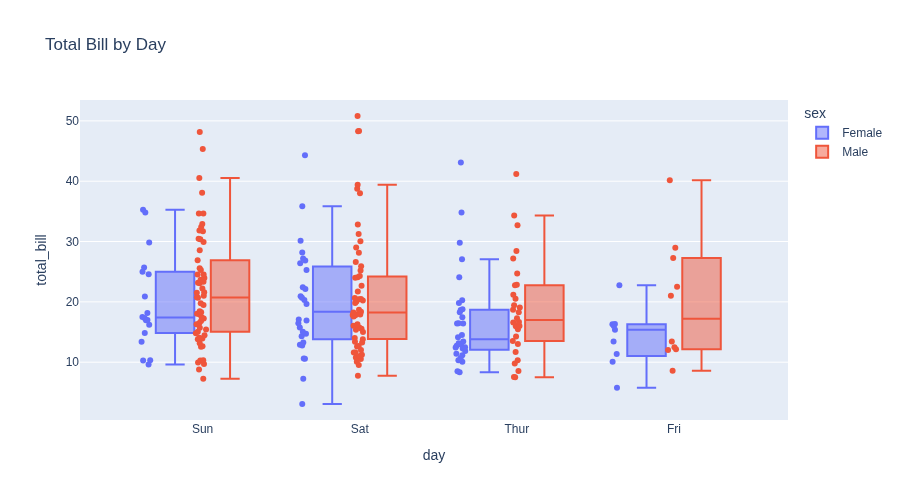

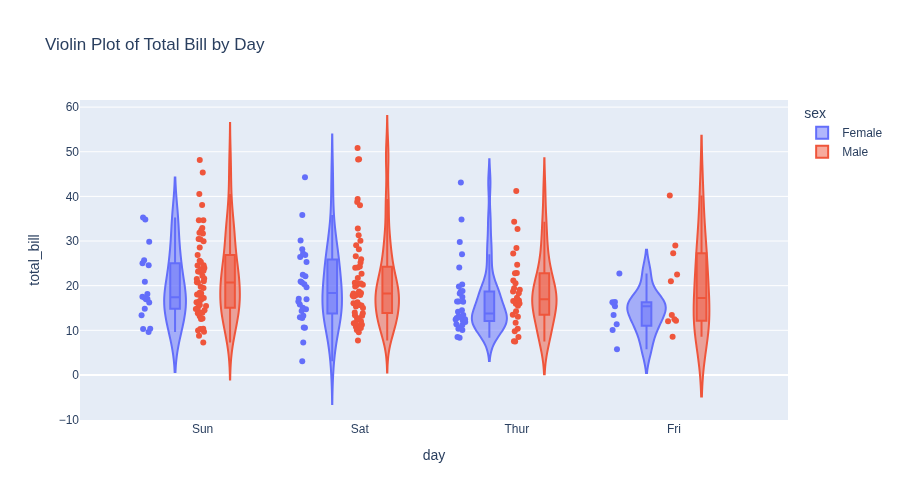

In [6]:
# Box plot
fig = px.box(
    tips, x='day', y='total_bill',
    color='sex', points='all',  # show all data points
    title='Total Bill by Day'
)
fig.show()

# Violin plot
fig = px.violin(
    tips, x='day', y='total_bill',
    color='sex', box=True,  # include box inside violin
    points='all',
    title='Violin Plot of Total Bill by Day'
)
fig.show()

## 3. 3D Charts

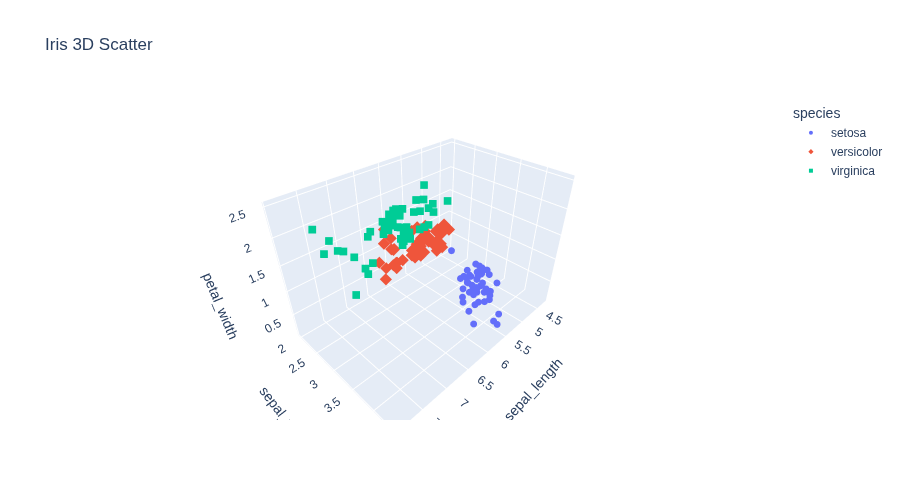

In [7]:
# 3D Scatter
iris = px.data.iris()
fig = px.scatter_3d(
    iris,
    x='sepal_length', y='sepal_width', z='petal_width',
    color='species', symbol='species',
    title='Iris 3D Scatter'
)
fig.update_traces(marker_size=4)
fig.show()

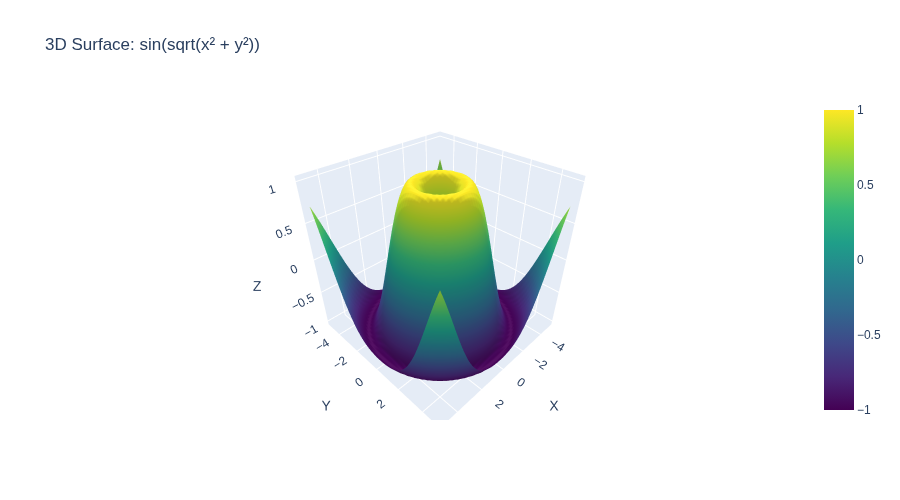

In [8]:
# 3D Surface
x = np.linspace(-5, 5, 50)
y = np.linspace(-5, 5, 50)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = go.Figure(data=[go.Surface(z=Z, x=X, y=Y, colorscale='Viridis')])
fig.update_layout(
    title='3D Surface: sin(sqrt(x² + y²))',
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z'
    )
)
fig.show()

## 4. Animated Charts

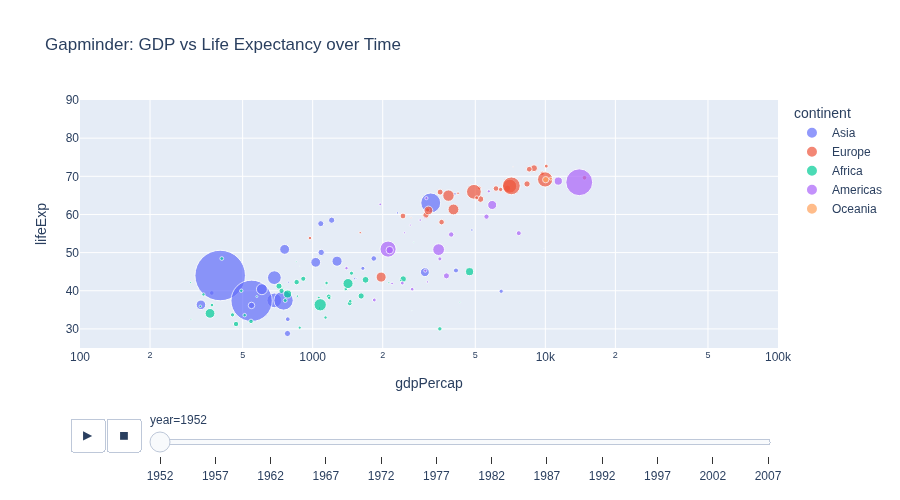

In [9]:
# Animated scatter (Gapminder famous animation)
fig = px.scatter(
    df, x='gdpPercap', y='lifeExp',
    animation_frame='year',
    animation_group='country',
    size='pop', color='continent',
    hover_name='country',
    log_x=True, size_max=55,
    range_x=[100, 100000],
    range_y=[25, 90],
    title='Gapminder: GDP vs Life Expectancy over Time'
)
fig.show()

## 5. Choropleth Maps

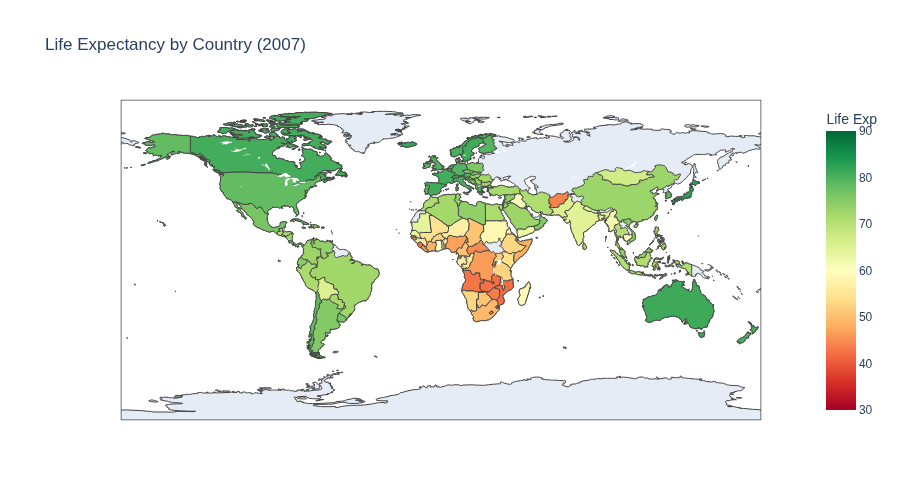

/tmp/ipykernel_20102/3020610978.py:17: DeprecationWarning: *choropleth_mapbox* is deprecated! Use *choropleth_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/
  fig = px.choropleth_mapbox(


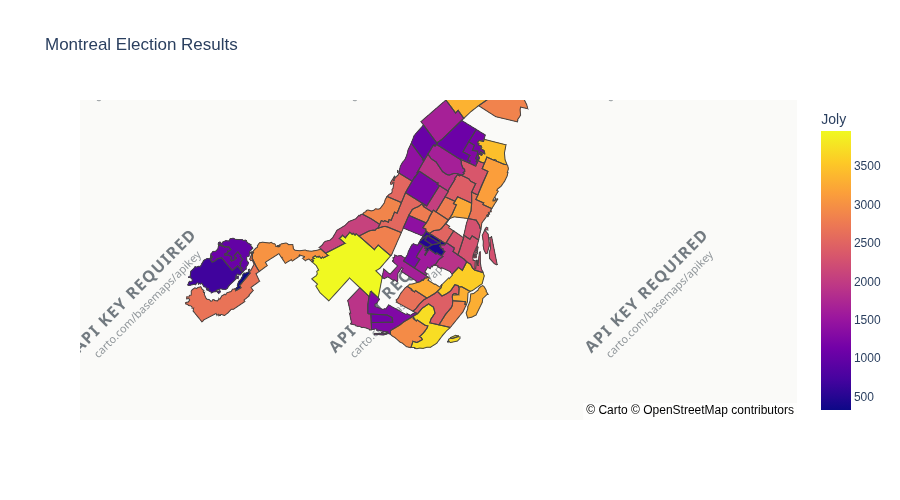

In [10]:
# Choropleth world map
fig = px.choropleth(
    df_2007,
    locations='iso_alpha',
    color='lifeExp',
    hover_name='country',
    color_continuous_scale='RdYlGn',
    range_color=[30, 90],
    title='Life Expectancy by Country (2007)'
)
fig.update_layout(coloraxis_colorbar_title='Life Exp')
fig.show()

# USA state map
us_data = px.data.election()
geojson = px.data.election_geojson()
fig = px.choropleth_mapbox(
    us_data, geojson=geojson,
    locations='district', color='Joly',
    featureidkey='properties.district',
    center={'lat': 45.5, 'lon': -73.6},
    mapbox_style='carto-positron',
    zoom=9,
    title='Montreal Election Results'
)
fig.show()

## 6. Subplots with Graph Objects

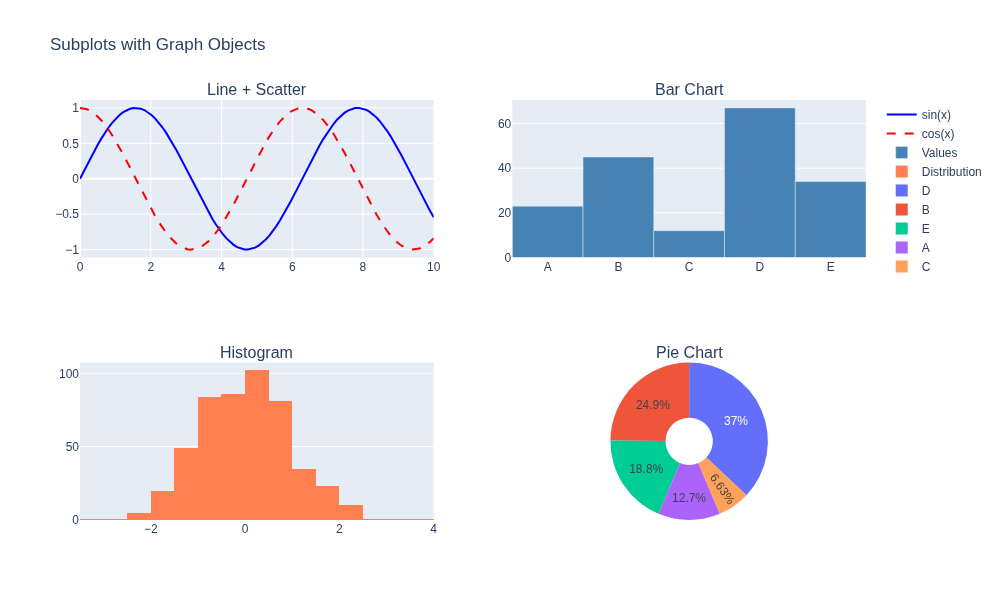

In [11]:
np.random.seed(42)
x = np.linspace(0, 10, 100)

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=['Line + Scatter', 'Bar Chart', 'Histogram', 'Pie Chart'],
    specs=[[{'type': 'scatter'}, {'type': 'bar'}],
           [{'type': 'histogram'}, {'type': 'pie'}]]
)

# Line plot
fig.add_trace(go.Scatter(x=x, y=np.sin(x), mode='lines', name='sin(x)', line=dict(color='blue')), row=1, col=1)
fig.add_trace(go.Scatter(x=x, y=np.cos(x), mode='lines', name='cos(x)', line=dict(color='red', dash='dash')), row=1, col=1)

# Bar chart
categories = ['A','B','C','D','E']
values = [23, 45, 12, 67, 34]
fig.add_trace(go.Bar(x=categories, y=values, marker_color='steelblue', name='Values'), row=1, col=2)

# Histogram
data_hist = np.random.randn(500)
fig.add_trace(go.Histogram(x=data_hist, nbinsx=30, marker_color='coral', name='Distribution'), row=2, col=1)

# Pie chart
fig.add_trace(go.Pie(labels=categories, values=values, hole=0.3, name='Pie'), row=2, col=2)

fig.update_layout(height=600, width=1000, title_text='Subplots with Graph Objects', showlegend=True)
fig.show()

## 7. Customization and Layout

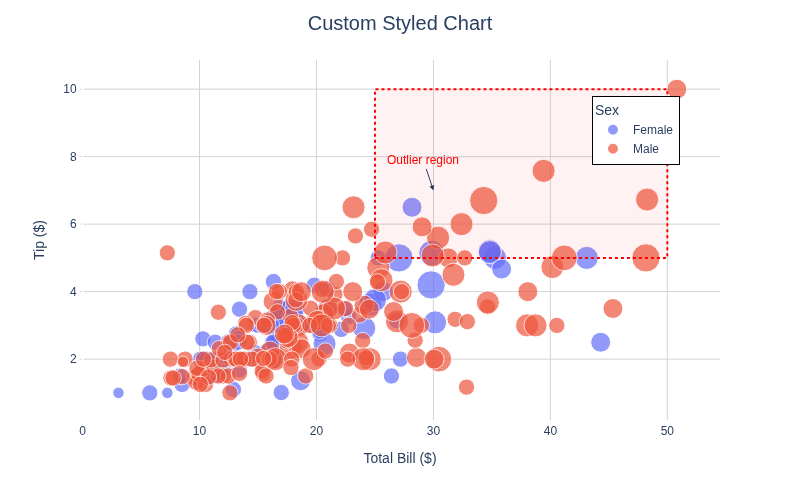

In [12]:
# Full layout customization
fig = px.scatter(tips, x='total_bill', y='tip', color='sex', size='size')

fig.update_layout(
    title=dict(text='Custom Styled Chart', font=dict(size=20), x=0.5),
    xaxis=dict(title='Total Bill ($)', gridcolor='lightgray', showline=True),
    yaxis=dict(title='Tip ($)', gridcolor='lightgray', showline=True),
    legend=dict(title='Sex', bordercolor='black', borderwidth=1, x=0.8, y=0.9),
    plot_bgcolor='white',
    paper_bgcolor='white',
    font=dict(family='Arial', size=12),
    hoverlabel=dict(bgcolor='white', font_size=12),
    width=800, height=500
)

# Add annotation
fig.add_annotation(
    x=30, y=7,
    text='Outlier region',
    showarrow=True,
    arrowhead=2,
    font=dict(size=12, color='red')
)

# Add shape (rectangle)
fig.add_shape(
    type='rect', x0=25, y0=5, x1=50, y1=10,
    line=dict(color='red', dash='dot'),
    fillcolor='rgba(255,0,0,0.05)'
)

fig.show()

## 8. Dash Building Dashboards

In [13]:
# Dash is a framework for building interactive web dashboards with Plotly
# pip install dash

# Basic Dash app structure:
DASH_APP_TEMPLATE = '''
import dash
from dash import dcc, html, Input, Output
import plotly.express as px
import pandas as pd

app = dash.Dash(__name__)

df = px.data.gapminder()

app.layout = html.Div([
    html.H1("Gapminder Dashboard", style={"textAlign": "center"}),

    dcc.Dropdown(
        id="continent-dropdown",
        options=[{"label": c, "value": c} for c in df["continent"].unique()],
        value="Asia",
        clearable=False
    ),

    dcc.Graph(id="life-exp-graph")
])

@app.callback(
    Output("life-exp-graph", "figure"),
    Input("continent-dropdown", "value")
)
def update_graph(selected_continent):
    filtered = df[df["continent"] == selected_continent]
    fig = px.scatter(
        filtered, x="gdpPercap", y="lifeExp",
        size="pop", color="country",
        hover_name="country", log_x=True,
        animation_frame="year",
        title=f"GDP vs Life Expectancy {selected_continent}"
    )
    return fig

if __name__ == "__main__":
    app.run_server(debug=True)
'''

print('Dash app template printed save as app.py and run with: python app.py')
print(DASH_APP_TEMPLATE)

Dash app template printed save as app.py and run with: python app.py

import dash
from dash import dcc, html, Input, Output
import plotly.express as px
import pandas as pd

app = dash.Dash(__name__)

df = px.data.gapminder()

app.layout = html.Div([
    html.H1("Gapminder Dashboard", style={"textAlign": "center"}),

    dcc.Dropdown(
        id="continent-dropdown",
        options=[{"label": c, "value": c} for c in df["continent"].unique()],
        value="Asia",
        clearable=False
    ),

    dcc.Graph(id="life-exp-graph")
])

@app.callback(
    Output("life-exp-graph", "figure"),
    Input("continent-dropdown", "value")
)
def update_graph(selected_continent):
    filtered = df[df["continent"] == selected_continent]
    fig = px.scatter(
        filtered, x="gdpPercap", y="lifeExp",
        size="pop", color="country",
        hover_name="country", log_x=True,
        animation_frame="year",
        title=f"GDP vs Life Expectancy {selected_continent}"
    )
    return fig

if __

## Additional Learning Resources

### Official Documentation
- **Plotly Python Docs**: https://plotly.com/python/
- **Plotly Express Reference**: https://plotly.com/python-api-reference/plotly.express.html
- **Graph Objects Reference**: https://plotly.com/python/graph-objects/
- **Dash Documentation**: https://dash.plotly.com/

### Tutorials
- **Plotly Tutorial** Charming Data (YouTube): https://www.youtube.com/c/CharmingData
- **Plotly Full Course** freeCodeCamp: https://www.youtube.com/watch?v=GGL6U0k8WYA
- **Plotly Express Tutorial**: https://plotly.com/python/plotly-express/

### Examples Gallery
- **Plotly Chart Gallery**: https://plotly.com/python/
- **Dash Example Index**: https://dash.gallery/Portal/